In [ ]:
### Keep following modules in session - bridge_service | summariser_module | topic_engine | structured_conversation.json (for local testing)
import os
import glob
import json
import time
from typing import List, Dict, Any
import urllib3
import decimal
from datetime import datetime, timezone
from pathlib import Path

from google.colab import userdata
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LassoCV
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, f1_score, confusion_matrix
import statsmodels.api as sm
import altair as alt

data_csv_path = '/content/drive/MyDrive/Datasets/flattened_topic_features.csv'

import bridge_service
import summariser_module
import topic_engine
from bridge_service import make_config_from_env, MoltbookMyceliumBridge
from summariser_module import summarize_for_moltbook
from topic_engine import (
    WindowManager,
    TopicDiscoveryEngine,
    CandidateIntelligenceEngine,
    CandidateValidationEngine,
    execute_governance_gate
)



print("modules import OK")
urllib3.disable_warnings()

In [ ]:
### For internediate code changes
import importlib
importlib.reload(bridge_service)
importlib.reload(summariser_module)
importlib.reload(topic_engine)

In [ ]:
# ---------- 0. Secrets ----------
_SECRET_ENV_MAP = {
    "LITELLM_API_KEY":               "LITELLM_API_KEY",
    "LITELLM_API_KEY2":              "LITELLM_API_KEY2",
    "LITELLM_USER_ID1":              "LITELLM_USER_ID1",
    "LITELLM_USER_ID2":              "LITELLM_USER_ID2",
    "MOLTBOOK_API_KEY":              "MOLTBOOK_API_KEY",
    "MOLTBOOK_API_KEY_FINANCEGUARD": "MOLTBOOK_API_KEY_FINANCEGUARD",
    "MOLTBOOK_API_KEY_CAREERMAX":    "MOLTBOOK_API_KEY_CAREERMAX",
    "MOLTBOOK_API_KEY_STUDENTLIFE":  "MOLTBOOK_API_KEY_STUDENTLIFE",
    "MOLTBOOK_API_KEY_RISKANALYST":  "MOLTBOOK_API_KEY_RISKANALYST",
}

missing = []
for secret_name, env_var in _SECRET_ENV_MAP.items():
    try:
        os.environ[env_var] = userdata.get(secret_name)
    except userdata.SecretNotFoundError:
        missing.append(secret_name)
    except userdata.NotebookAccessError:
        raise RuntimeError(
            f"Notebook not granted access to secret '{secret_name}'. "
            "Toggle 'Notebook access' ON in the Colab Secrets panel."
        )
    except Exception as e:
        print(f"⚠️ Secret '{secret_name}' not loaded: {e}")

if missing:
    raise RuntimeError(f"Add these secrets in the Colab Secrets panel: {missing}")


os.environ['MOLTBOOK_BASE_URL'] = 'https://www.moltbook.com/api/v1'
os.environ['MOLTBOOK_SUBMOLT'] = 'secure-dev-logic'
os.environ['MOLTBOOK_SUBMOLT_DISPLAY'] = 'Private Agent Logic Exchange'
os.environ['MOLTBOOK_SUBMOLT_DESCRIPTION'] = 'A restricted room for back-end multi-agent synchronization.'
os.environ['MYCELIUM_BASE_URL'] = 'https://argue-cant-billing-endorsed.trycloudflare.com'
os.environ["MYCELIUM_ROOM"] = "moltbook-mycelium-demo"
os.environ['MYCELIUM_SENDER'] = 'amlan'
os.environ["BRIDGE_STATE_PATH"] = "bridge_state.json"

os.environ["LITELLM_MODEL"] = "azure/gpt-4o-mini"
os.environ["LITELLM_URL"] = "https://litellm.prod.outshift.ai/v1/chat/completions"

os.environ.setdefault(
    "SCENARIO_FACTS",
    "ASU has a $25,000/year scholarship and NYU has no aid.",
)

os.environ.setdefault("TARGET_POST_ID", "53fff94b-6542-4b91-bdcc-aabf9c9d237a")
os.environ.setdefault("EXPECTED_TOPIC_TITLE", "")

# DEMO TOGGLE: Set to "True" to use structured_conversation.json instead of Live Moltbook API
os.environ.setdefault("USE_LOCAL_JSON", "True")

cfg = make_config_from_env()
bridge = MoltbookMyceliumBridge(cfg)
print("###################################################")
print("\n[SYSTEM BOOTSTRAP] Parameters loaded and Bridge configured.")
print("###################################################")
print(cfg)

submolt = bridge.ensure_submolt()
print("###################################################")
print("environment checks done")
print("###################################################")
print("SUBMOLT READY PROFILE:", submolt)

print(bridge.moltbook.list_submolt_posts(cfg.submolt_name, limit=5))
# print(bridge.mycelium.get_messages(cfg.mycelium_room, limit=5))

posts = bridge.moltbook.list_submolt_posts(cfg.submolt_name, limit=50)
print("###################################################")
print("list submolt posts done")
print("###################################################")

# ---------- post title verification ----------
expected_title = os.environ.get("EXPECTED_TOPIC_TITLE", "").strip()
if expected_title:
    print("###################################################")
    print("post name discovery done/ title verification")
    print("###################################################")
    for p in posts:
        print(p.get("id"), "|", p.get("title") or p.get("name"))
        title = (p.get("title") or p.get("name") or "").strip()
        if title.lower() == expected_title.lower():
            print("FOUND:", p)
            break
    else:
        raise ValueError(f"Expected topic title not found: {expected_title!r}")
else:
    print("NOTE: EXPECTED_TOPIC_TITLE not set — skipping title verification.")


# ---------- Conversation event Stream Ingestion & Autonomous Topic Mining [Live vs demo] ----------
USE_LOCAL_JSON = os.environ.get("USE_LOCAL_JSON", "False").lower() == "true"
target_post_id = os.environ["TARGET_POST_ID"]
# target_post_id = os.environ.get("TARGET_POST_ID", "53fff94b-6542-4b91-bdcc-aabf9c9d237a")
print("###################################################")
print(f"Fetching live event stream for Thread ID: {target_post_id}...")
print("###################################################")

print("\n" + "=" * 80)
if USE_LOCAL_JSON:
    print(f"DEMO MODE: Loading static stream from 'structured_conversation.json'...")
    try:
        with open("structured_conversation.json", "r") as f:
            raw_stream = json.load(f)
        # Sort local JSON chronologically
        live_event_stream = sorted(raw_stream, key=lambda x: x.get("created_at", ""))
        print(f"[STREAM INGESTION COMPLETE] Loaded {len(live_event_stream)} events from local JSON.")
    except Exception as e:
        raise RuntimeError(f"Failed to load structured_conversation.json: {e}")
else:
    print(f"LIVE MODE: Fetching event stream from Moltbook Thread ID: {target_post_id}...")
    submolt = bridge.ensure_submolt()

    def flatten_comment_tree(comment_node, parent_id=None):
        """
        Recursively unpacks nested 'replies' into a flat list, preserving
        explicit parent_id references for downstream thread tracing.
        """
        flat = []
        # Set parent_id on the node if not present
        node_copy = dict(comment_node)
        if parent_id and not node_copy.get("parent_id"):
            node_copy["parent_id"] = parent_id

        # Extract nested replies before removing them from the flat representation
        nested_replies = node_copy.pop("replies", []) or []

        # Tag as comment event
        node_copy["post_id"] = target_post_id
        node_copy["event_type"] = "COMMENT_CREATED"
        flat.append(node_copy)

        # Recursively traverse any child replies
        current_node_id = node_copy.get("id")
        for child in nested_replies:
            flat.extend(flatten_comment_tree(child, parent_id=current_node_id))

        return flat


        try:
            # 1. Fetch Root Post
            root_post_response = bridge.moltbook._get(f"/posts/{target_post_id}")
            root_post = root_post_response.get("post", {})
            root_post["event_type"] = "POST_CREATED"
            root_post["parent_id"] = None

            # 2. Paginated Fetch across all offsets
            all_comments_raw = []
            offset = 0
            limit = 20

            while True:
                res = bridge.moltbook._get(f"/posts/{target_post_id}/comments?limit={limit}&offset={offset}")
                batch = res.get("comments", [])
                if not batch:
                    break

                all_comments_raw.extend(batch)
                print(f" ├── Fetched offset {offset}: retrieved {len(batch)} parent comments")

                has_more = res.get("has_more", False)
                if not has_more or len(batch) < limit:
                    break

                offset += limit

            # 3. Recursively flatten all parent comments and nested agent child replies
            all_flat_comments = []
            for parent_comment in all_comments_raw:
                all_flat_comments.extend(flatten_comment_tree(parent_comment, parent_id=root_post.get("id")))

            # 4. Sort strictly forward in time (Chronological Order: oldest -> newest)
            all_flat_comments.sort(key=lambda x: x.get("created_at", ""))

            # 5. Build final Chronological Event Stream (Root post first, then all comments)
            live_event_stream = [root_post] + all_flat_comments

            print(f"\n[STREAM INGESTION COMPLETE]")
            print(f"Total stream events assembled: {len(live_event_stream)} (1 root post + {len(all_flat_comments)} total hierarchical comments)")

            # Quick participant check
            authors_found = set()
            for ev in live_event_stream:
                a = ev.get("author", {})
                authors_found.add(a.get("name") if isinstance(a, dict) else str(a))
            print(f"Unique agents/authors discovered in stream: {sorted(list(authors_found))}")

        except Exception as e:
            raise RuntimeError(f"Failed to fetch live stream from Moltbook: {e}")

In [ ]:
# =====================================================================
# ATM PIPELINE RUNNER UTILITY
# =====================================================================
def process_conversation_stream_through_atm(
    event_stream: list,
    thread_id: str,
    window_limit: int = 5,
    scoring_threshold: float = 0.60,
    api_delay: float = 0.3
) -> dict:
    """
    Executes Stages 1 through 6 of the ATM pipeline over a supplied conversation stream.
    Reuses the exact engine classes imported in Cell 3 and tested in Cell 5.
    """
    # 1. State Isolation of each conversation file to prevent context bleed: Instantiates fresh engine memory instance per conversation
    local_window_mgr = WindowManager(window_limit=window_limit, dedup_cache_size=500)
    local_discovery_engine = TopicDiscoveryEngine()
    local_intel_engine = CandidateIntelligenceEngine()

    final_window = None

    # Stages 1 - 3: Ingestion & Topic Discovery
    for raw_event in event_stream:
        time.sleep(api_delay)  # Rate limit protection for LiteLLM
        cur_window = local_window_mgr.process_event(raw_event)
        if not cur_window:
            continue
        final_window = cur_window
        latest_event = cur_window['messages'][-1]

        active_topics = local_discovery_engine.discover_topics(cur_window, latest_event)
        active_ids = [t['topic_id'] for t in active_topics if t.get('topic_status') == 'ACTIVE']
        local_window_mgr.sync_topic_refs(cur_window['thread_id'], active_ids)

    # Stages 4 & 5: Converged State Topic Enrichment & LLM Actionability Scoring
    discovered_topics = list(local_discovery_engine.active_topics.values())
    print(f" ├── Stream Ingestion Complete. Active clusters discovered: {len(discovered_topics)}")
    scored_candidates = []

    for topic in discovered_topics:
        time.sleep(api_delay)
        # S4: Deep signal extraction (objectives, constraints, conflicts)
        enriched = local_intel_engine.enrich_topic(topic, final_window or {})
        # S5: Scoring target variable extraction
        scored = local_intel_engine.score_candidate(enriched, threshold=scoring_threshold)
        scored_candidates.append(scored)

    # Stage 6: Deterministic Multi-Key Ranking
    ranked_result = local_intel_engine.rank_candidates(
        qualified_candidates=scored_candidates,
        thread_id=thread_id
    )

    return ranked_result

print("[✓] Modular ATM Pipeline Runner registered and ready.")

In [ ]:
# =====================================================================
# SYNTHETIC-CONVERSATION BATCH EXECUTION VIA ATM PIPELINE LOOP AND PAYLOAD SERIALISATION
# =====================================================================
# File Handling & Batch Ingestion Setup - Mount Drive beforehand
# Directories setup
CONVERSATIONS_DIR = Path("/content/drive/MyDrive/Datasets/generated_conversations_v1") # Directory holding the 50 JSON files
OUTPUT_PAYLOADS_DIR = Path("/content/enriched_topic_payloads") # Output destination
OUTPUT_PAYLOADS_DIR.mkdir(parents=True, exist_ok=True)

# 1. Discover JSON conversation files
target_files = sorted(glob.glob(str(CONVERSATIONS_DIR / "*.json")))[:50]

# Failsafe: If folder is not mounted or directory is empty, Fallback to the active demo conversation
if not target_files:
    if os.path.exists("structured_conversation.json"):
        print("[!] No files in /content/generated_conversations_v1. Using 'structured_conversation.json' for testing.")
        target_files = ["structured_conversation.json"]
    else:
        raise FileNotFoundError(f"Please place conversation files into {CONVERSATIONS_DIR}")

# Limit to target of 50 conversations
target_files = target_files[:50]
print(f"[*] Starting Batch Execution across {len(target_files)} conversation file(s)...")

def craft_candidate_payload(topic_id, rank, designation, scored_details):
    """Crafts payload strictly matching Last_experiment_topic_payload_enriched.json candidate schema."""
    return {
        "topic_id": topic_id,
        "rank": rank,
        "score": scored_details.get("score", 0.0),
        "designation": designation,
        "candidate_details": scored_details
    }

total_payloads_saved = 0

# 2. State Isolation & Outer Iteration Loop: Process each conversation independently
for conv_idx, file_path in enumerate(target_files, start=1):
    file_stem = Path(file_path).stem
    print(f"\n>>> [{conv_idx}/{len(target_files)}] Processing file: {file_stem}")

    with open(file_path, "r", encoding="utf-8") as f:
        raw_stream = json.load(f)

    # Sort chronologically to preserve reply chains
    sorted_stream = sorted(raw_stream, key=lambda x: x.get("created_at", ""))
    if not sorted_stream:
        continue

    # Resolve thread ID from root post - Track the active thread_id from the root event
    root_event = sorted_stream[0]
    thread_id = str(root_event.get("post_id") or root_event.get("id") or f"thread-{conv_idx}")


    # CALL THE INTEGRATED ATM PIPELINE RUNNER
    ranked_result = process_conversation_stream_through_atm(
        event_stream=sorted_stream,
        thread_id=thread_id
    )

    # Save each ranked topic candidate as its own JSON artifact (Goal: 150 files)
    # Output Serialization: Programmatically craft & serialize the 3 candidate payloads
    candidates = ranked_result.get("candidates", [])
    for cand in candidates:
        t_id = cand.get("topic_id")
        rank_val = cand.get("rank")
        designation_val = cand.get("designation")
        details = cand.get("candidate_details")

        payload = craft_candidate_payload(t_id, rank_val, designation_val, details)

        output_file = OUTPUT_PAYLOADS_DIR / f"conv_{conv_idx:02d}_{thread_id}_{file_stem}_{t_id}_enriched.json"
        with open(output_file, "w", encoding="utf-8") as out_f:
            json.dump(payload, out_f, indent=2)

        total_payloads_saved += 1

    print(f" └── Extracted and saved {len(candidates)} candidate payload(s) for thread {thread_id}")
    # Optional: Save conversation-level aggregate payload
    agg_filename = OUTPUT_PAYLOADS_DIR / f"conv_{conv_idx:02d}_{thread_id}_ranked.json"
    with open(agg_filename, "w") as agg_f:
        json.dump(ranked_result, agg_f, indent=2)

print("\n" + "=" * 80)
print(f"[✓] BATCH RUN COMPLETED: Successfully saved totally {total_payloads_saved} generated enriched candidate payloads.")
print(f"Artifacts Directory: {OUTPUT_PAYLOADS_DIR.resolve()}")
print("=" * 80)

In [ ]:
!zip -r enriched_topic_payloads.zip enriched_topic_payloads/

**Evaluation of Scoring Rubric and the dimensions:**

1st Stage - Engineering and Heuristics | Top down approach -> [Documentation](https://cisco-my.sharepoint.com/:w:/r/personal/amlsaman_cisco_com/_layouts/15/Doc.aspx?sourcedoc=%7B8DA0D8C0-C8FC-4EA6-85A6-0B426741C712%7D&file=Empirical%20validation_DRAFT.docx&fromShare=true&action=default&mobileredirect=true):

Based on our intuition, domain logic, rules etc [ feature engineering and system engineering math ]

######################################

2nd Stage - Scientific | Bottom up approach (Follow along this notebook):

Data > Data science+ML approaches > solved multicollinearity > reduced redundant dimensions > discovered useful features > modelled the LLM scores



# Observations via heuristics:-

Based on the observations on the initial outcome of evaluating the empirical formulas engineered for validating the LLM scoring rubric and the 8 dimensions, we identified multicollinearity in many instances - i.e., two scoring dimensions are moving in lockstep across the dataset.

Here is the strategic breakdown of where the redundancies hide

1. Dropping of Penalties:

a. Resolution Penalty-> Roll into Unresolvednes
b. Drop Routine Conversation Penalty -> Roll into Relevance/ Conflict Strength
c. Drop Existing Work Penalty -> Roll into Coordination Value

2. Merge Overlapping Drivers - Feature engineering:

a. Merge Conflict Strength and Coordination Value
b. Merge Relevance and Supporting Evidence

### Mathemical, Data Science & ML  approaches:-

In [ ]:
## =====================================================================
# DATA FLATTENING (CSV COMPILATION)
# =====================================================================

PAYLOADS_DIR = Path("/content/enriched_topic_payloads")
OUTPUT_CSV_PATH = Path("/content/flattened_topic_features.csv")

def map_categorical(val: str, field_name: str):
    """Maps categorical string states to standard empirical float values."""
    if not val:
        return 0.0
    val = str(val).upper()
    if field_name == "owner_status":
        mapping = {"CLEAR": 1.0, "SHARED_OR_UNCLEAR": 0.5, "UNASSIGNED": 0.0}
        return mapping.get(val, 0.5)
    elif field_name == "resolution_status":
        mapping = {"RESOLVED": 1.0, "UNRESOLVED": 0.0}
        return mapping.get(val, 0.0)
    return 0.0

payload_files = sorted(glob.glob(str(PAYLOADS_DIR / "*_enriched.json")))
flattened_records = []

for p_path in payload_files:
    with open(p_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    details = data.get("candidate_details", {})
    enriched = details.get("enriched_topic", {})
    breakdown = details.get("score_breakdown", {})

    record = {
        # Base Identifiers & Target Variable
        "file_name": Path(p_path).name,
        "topic_id": data.get("topic_id"),
        "rank": data.get("rank"),
        "target_actionability_score": float(data.get("score", details.get("score", 0.0))),

        # 8 Empirical Dimensions
        "relevance": float(breakdown.get("relevance", 0.0)),
        "unresolvedness": float(breakdown.get("unresolvedness", 0.0)),
        "conflict_strength": float(breakdown.get("conflict_strength", 0.0)),
        "supporting_evidence": float(breakdown.get("supporting_evidence", 0.0)),
        "coordination_value": float(breakdown.get("coordination_value", 0.0)),
        "resolution_penalty": float(breakdown.get("resolution_penalty", 0.0)),
        "routine_conversation_penalty": float(breakdown.get("routine_conversation_penalty", 0.0)),
        "existing_work_penalty": float(breakdown.get("existing_work_penalty", 0.0)),

        # Array length counts (Evidence Volumes)
        "num_objectives": len(enriched.get("objectives", [])),
        "num_hard_constraints": len(enriched.get("hard_constraints", [])),
        "num_soft_preferences": len(enriched.get("soft_preferences", [])),
        "num_conflicts": len(enriched.get("conflicts", [])),
        "num_unresolved_questions": len(enriched.get("unresolved_questions", [])),
        "num_supporting_messages": len(enriched.get("supporting_message_ids", [])),
        "num_participants": len(enriched.get("participant_ids", [])),

        # Categoricals MAPPED to numeric float values
        "owner_status_val": map_categorical(enriched.get("owner_status"), "owner_status"),
        "resolution_status_val": map_categorical(enriched.get("resolution_status"), "resolution_status"),
        "evidence_completeness": float(enriched.get("evidence_completeness", 0.0))
    }
    flattened_records.append(record)

df = pd.DataFrame(flattened_records)
# Save the full feature set for correlation & regularization modeling
df.to_csv(OUTPUT_CSV_PATH, index=False)

print(f"[✓] Feature Engineering Complete: {len(df)} records compiled. Shape = {df.shape} (Expected: 150 rows)")
print(f"[✓] Flat CSV Dataset generated at: {OUTPUT_CSV_PATH}")
print(f"[✓] Primary dimensions verified:")
print(df[["topic_id", "score", "relevance", "unresolvedness", "conflict_strength",
         "supporting_evidence", "coordination_value", "resolution_penalty",
         "routine_conversation_penalty", "existing_work_penalty"]].head(3))

#Dimension Reduction - Approach 1 (PCA)

In [ ]:
def run_core_pca_reduction(csv_path, variance_threshold=0.90):
    # 1. Explicitly define and isolate the 8 core rubric dimensions
    CORE_8_RUBRIC = [
        'relevance', 'unresolvedness', 'conflict_strength',
        'supporting_evidence', 'coordination_value',
        'resolution_penalty', 'routine_conversation_penalty', 'existing_work_penalty'
    ]

    df = pd.read_csv(csv_path)
    X_core = df[CORE_8_RUBRIC]

    # 2. Drop zero-variance columns prior to scaling
    variances = X_core.var()
    zero_var_cols = variances[variances == 0].index.tolist()
    X_active = X_core.drop(columns=zero_var_cols)
    feature_names = X_active.columns.tolist()

    print(f"Dropped Zero-Variance Rubric Dimensions prior to PCA: {zero_var_cols}\n")

    # 3. Normalize the active rubric dimensions (mean=0, variance=1)
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_active)

    # 4. Instantiate and fit PCA
    pca = PCA()
    pca.fit(X_scaled)

    # 5. Extract explained variance and compute cumulative sum
    explained_variance = pca.explained_variance_ratio_
    cumulative_variance = np.cumsum(explained_variance)

    # 6. Identify optimal components to hit the threshold
    n_components = np.argmax(cumulative_variance >= variance_threshold) + 1

    print(f"Total active rubric features evaluated: {len(feature_names)}")
    print(f"Minimum components to explain >= {variance_threshold*100}% variance: {n_components}\n")

    print("Cumulative Variance Explained:")
    for i, cum_var in enumerate(cumulative_variance):
        print(f"Component {i+1}: {cum_var*100:.2f}%")

    # Generate and save scree plot
    plt.figure(figsize=(8, 5))
    plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='-', color='b')
    plt.axhline(y=variance_threshold, color='r', linestyle='--', label=f'{variance_threshold*100}% Threshold')
    plt.axvline(x=n_components, color='g', linestyle='--', label=f'Optimal Components: {n_components}')
    plt.title('PCA: Cumulative Explained Variance (Core Rubric)')
    plt.xlabel('Number of Principal Components')
    plt.ylabel('Cumulative Explained Variance')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.tight_layout()
    plt.savefig('core_pca_cumulative_variance.png')
    plt.close()

    # 7. Interactive Altair Scree Plot
    pca_df = pd.DataFrame({
        'Component': range(1, len(cumulative_variance) + 1),
        'Cumulative Variance': cumulative_variance
    })

    base = alt.Chart(pca_df).encode(x=alt.X('Component:O', title='Number of Principal Components'))

    line = base.mark_line(color='blue').encode(y=alt.Y('Cumulative Variance:Q', title='Cumulative Explained Variance'))

    points = base.mark_point(color='blue', filled=True, size=60).encode(
        y='Cumulative Variance:Q',
        tooltip=[alt.Tooltip('Component:O'), alt.Tooltip('Cumulative Variance:Q', format='.2%')]
    )

    threshold_line = alt.Chart(pd.DataFrame({'threshold': [variance_threshold]})).mark_rule(
        color='red', strokeDash=[5, 5]
    ).encode(y='threshold:Q')

    chart = (line + points + threshold_line).properties(
        title='PCA: Cumulative Explained Variance (Core Rubric)',
        width=600,
        height=400
    ).interactive()

    display(chart)

    return pca, X_scaled, n_components

# Execute the pipeline
pca_model, scaled_data, optimal_components = run_core_pca_reduction(data_csv_path)

Dropped Zero-Variance Rubric Dimensions prior to PCA: ['resolution_penalty', 'routine_conversation_penalty', 'existing_work_penalty']

Total active rubric features evaluated: 5
Minimum components to explain >= 90.0% variance: 3

Cumulative Variance Explained:
Component 1: 73.36%
Component 2: 86.61%
Component 3: 94.24%
Component 4: 97.89%
Component 5: 100.00%


alt.LayerChart(...)

#Dimension Reduction - Approach 2 (Spearman Correlation)

In [ ]:
def run_correlation_reduction(csv_path, threshold=0.85):
    # 1. Load data
    df = pd.read_csv(csv_path)

    # Merge overlapping positive signals based on the strategic heuristic
    # df['strategic_relevance'] = df[['relevance', 'supporting_evidence']].mean(axis=1)
    # df['negotiation_need'] = df[['conflict_strength', 'coordination_value']].mean(axis=1)

    # Explicitly define the new engineered rubric (replacing the merged constituents)
    # ENGINEERED_RUBRIC = [
    #     'strategic_relevance', 'unresolvedness', 'negotiation_need',
    #     'resolution_penalty', 'routine_conversation_penalty', 'existing_work_penalty'
    # ]

    CORE_8_RUBRIC = [
        'relevance', 'unresolvedness', 'conflict_strength',
        'supporting_evidence', 'coordination_value',
        'resolution_penalty', 'routine_conversation_penalty', 'existing_work_penalty'
    ]

    # X_core = df[ENGINEERED_RUBRIC]
    X_core = df[CORE_8_RUBRIC]

    # 2. Identify and drop zero-variance dimensions (This mathematically catches & drops the 3 penalties)
    variances = X_core.var()
    zero_var_cols = variances[variances == 0].index.tolist()
    # active_features = [f for f in ENGINEERED_RUBRIC if f not in zero_var_cols]
    active_features = [f for f in CORE_8_RUBRIC if f not in zero_var_cols]

    print(f"Dropped Zero-Variance Rubric Dimensions: {zero_var_cols}\n")

    # 3. Execute Spearman rank correlation on active dimensions
    corr_matrix = df[active_features].corr(method='spearman')

    # 4. Generate and save correlation heatmap
    plt.figure(figsize=(8, 6))
    sns.heatmap(corr_matrix, annot=True, fmt=".3f", cmap='coolwarm', vmin=-1, vmax=1)
    plt.title('Spearman Correlation Heatmap')
    plt.tight_layout()
    plt.savefig('engineered_rubric_correlation_heatmap.png')
    plt.close()

    # 4. Interactive Altair Heatmap
    corr_df = corr_matrix.reset_index().melt(id_vars='index')
    corr_df.columns = ['Feature 1', 'Feature 2', 'Correlation']

    base = alt.Chart(corr_df).encode(
        x=alt.X('Feature 1:O', title=None),
        y=alt.Y('Feature 2:O', title=None)
    )

    heatmap = base.mark_rect().encode(
        color=alt.Color('Correlation:Q', scale=alt.Scale(scheme='redblue', domain=[-1, 1])),
        tooltip=[
            alt.Tooltip('Feature 1:O'),
            alt.Tooltip('Feature 2:O'),
            alt.Tooltip('Correlation:Q', format='.3f')
        ]
    )

    text = base.mark_text(baseline='middle').encode(
        text=alt.Text('Correlation:Q', format='.3f'),
        color=alt.condition(
            abs(alt.datum.Correlation) > 0.5,
            alt.value('white'),
            alt.value('black')
        )
    )

    chart = (heatmap + text).properties(
        title='Spearman Correlation Heatmap',
        width=500,
        height=500
    )

    display(chart)

    # 5. Extract pairs >= threshold and sort descending by correlation strength
    corr_pairs = []
    for i in range(len(corr_matrix.columns)):
        for j in range(i + 1, len(corr_matrix.columns)):
            val = corr_matrix.iloc[i, j]
            if abs(val) >= threshold:
                corr_pairs.append((abs(val), corr_matrix.columns[i], corr_matrix.columns[j], val))

    corr_pairs.sort(reverse=True, key=lambda x: x[0])
    print("....................")
    print("Correleated pairs:")
    print("....................")
    print(corr_pairs)
    print("....................")
    # 6. Stateful greedy elimination using direct variance comparison + DOMAIN OVERRIDE
    final_drops = set()
    print(f"Highly Correlated Core rubric feature Pairs (>= {threshold}):")
    if not corr_pairs:
        print("- None found. The features are orthogonal.")

    for _, f1, f2, val in corr_pairs:
        # Stateful greedy check: skip if already eliminated
        if f1 in final_drops or f2 in final_drops:
            continue

        # Standard variance tie-breaker for any other non-protected features
        if f1 not in final_drops and f2 not in final_drops:
            drop = f1 if variances[f1] < variances[f2] else f2
            final_drops.add(drop)
            print(f"- {f1} & {f2} (r = {val:.3f}) -> Dropped: {drop}")

    surviving_features = [f for f in active_features if f not in final_drops]

    print("\nFinal Dropped Collinear Signals:", sorted(list(final_drops)))
    print("Final Surviving Core Rubric Dimensions:", surviving_features)

    return surviving_features, list(final_drops), zero_var_cols

# Execute the pipeline
surviving_features, dropped_features, zero_variance_features = run_correlation_reduction(data_csv_path)

Dropped Zero-Variance Rubric Dimensions: ['resolution_penalty', 'routine_conversation_penalty', 'existing_work_penalty']



alt.LayerChart(...)

....................
Correleated pairs:
....................
[(np.float64(0.88661478676703), 'relevance', 'conflict_strength', np.float64(0.88661478676703)), (np.float64(0.8612211445105173), 'unresolvedness', 'conflict_strength', np.float64(0.8612211445105173))]
....................
Highly Correlated Core rubric feature Pairs (>= 0.85):
- relevance & conflict_strength (r = 0.887) -> Dropped: relevance
- unresolvedness & conflict_strength (r = 0.861) -> Dropped: unresolvedness

Final Dropped Collinear Signals: ['relevance', 'unresolvedness']
Final Surviving Core Rubric Dimensions: ['conflict_strength', 'supporting_evidence', 'coordination_value']


# Observation - Dimentionality Reduction:
The PCA output confirms that the theoretical dimensionality floor for our 5 active rubric signals is exactly 3. Attempting to compress the data into 2 dimensions would only capture 86.61% of the variance, missing our 90% threshold. Capturing 3 dimensions retains a robust 94.24% of the underlying signal.

1/2 Conclusion:


Approach 1 (PCA) proved that 3 latent signals mathematically govern the dataset.

Approach 2 (Correlation) identified exactly 3 human-readable dimensions (conflict_strength, supporting_evidence, coordination_value) to carry that signal without severe collinearity.

# LLM Score modeling - Approach 1 (LassoCV)

In [ ]:
### LassoCV Regression

def run_lasso_program(csv_path, selected_features):
    # 1. Load data and isolate the validated DR phase surviving features
    df = pd.read_csv(csv_path)
    X = df[selected_features]
    y = df['target_actionability_score']

    # 2. Apply sample weights to mitigate the 0.56 baseline cluster
    score_counts = y.value_counts()
    inv_freq_map = 1.0 / score_counts
    inv_freq_map = inv_freq_map / inv_freq_map.mean()
    sample_weights = y.map(inv_freq_map).values

    # 3. Standardize features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # 4. Fit LassoCV independently
    lasso = LassoCV(cv=5, random_state=42, alphas=np.logspace(-5, 1, 200))
    lasso.fit(X_scaled, y, sample_weight=sample_weights)

    # 5. Generate predictions and evaluate performance
    predictions = lasso.predict(X_scaled)
    mse = mean_squared_error(y, predictions, sample_weight=sample_weights)

    # 6. Check for mathematically impossible scores
    boundary_violations = np.sum((predictions < 0.0) | (predictions > 1.0))

    print("--- LassoCV Program Results ---")
    print(f"Weighted MSE: {mse:.4f}")
    print(f"Boundary Violations (<0.0 or >1.0): {boundary_violations} out of {len(predictions)} predictions\n")

    # Interactive Coefficient Chart
    coef_df = pd.DataFrame({
        'Feature': selected_features,
        'Weight': lasso.coef_
    }).sort_values(by='Weight', key=abs, ascending=False)

    chart = alt.Chart(coef_df).mark_bar().encode(
        x=alt.X('Weight:Q', title='Coefficient Weight (Standardized)'),
        y=alt.Y('Feature:O', sort='-x', title=None),
        color=alt.Color('Weight:Q', scale=alt.Scale(scheme='viridis')),
        tooltip=['Feature', alt.Tooltip('Weight', format='.4f')]
    ).properties(
        title='LassoCV Feature Importance',
        width=500,
        height=200
    )
    display(chart)

    coefficients = pd.Series(lasso.coef_, index=selected_features)
    print("Feature Weights (Standardized Scale):")
    print(coefficients.sort_values(key=abs, ascending=False))

    return lasso, scaler, predictions

# The 3 mathematically validated features from DR Phase
phase_dr_survivors = surviving_features
lasso_model, lasso_scaler, lasso_preds = run_lasso_program(data_csv_path, phase_dr_survivors)

--- LassoCV Program Results ---
Weighted MSE: 0.0004
Boundary Violations (<0.0 or >1.0): 0 out of 172 predictions



alt.Chart(...)

Feature Weights (Standardized Scale):
conflict_strength      0.113945
supporting_evidence    0.040063
coordination_value     0.031245
dtype: float64


#LLM Score modeling - Approach 2 (GLM)

In [ ]:
### Bounded Curve Fitting - Generalized Linear Model

def run_glm_program(csv_path, selected_features):
    # 1. Load data and isolate the validated Phase 1 features
    df = pd.read_csv(csv_path)
    X = df[selected_features]
    y = df['target_actionability_score']

    # 2. Apply identical sample weights
    score_counts = y.value_counts()
    inv_freq_map = 1.0 / score_counts
    inv_freq_map = inv_freq_map / inv_freq_map.mean()
    sample_weights = y.map(inv_freq_map).values

    # 3. Standardize features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    X_scaled_df = pd.DataFrame(X_scaled, columns=selected_features)
    X_const = sm.add_constant(X_scaled_df)

    # 4. Fit the Binomial GLM independently
    glm_model = sm.GLM(
        endog=y,
        exog=X_const,
        family=sm.families.Binomial(),
        freq_weights=sample_weights
    )
    results = glm_model.fit()

    # 5. Generate predictions and evaluate performance
    predictions = results.predict(X_const)
    mse = mean_squared_error(y, predictions, sample_weight=sample_weights)

    # 6. Check for mathematically impossible scores
    boundary_violations = np.sum((predictions < 0.0) | (predictions > 1.0))

    print("--- Bounded GLM Program Results ---")
    print(f"Weighted MSE: {mse:.4f}")
    print(f"Boundary Violations (<0.0 or >1.0): {boundary_violations} out of {len(predictions)} predictions\n")

    print("Feature Weights (Logit Scale):")
    print(results.params)

    return results, scaler, predictions

# The 3 mathematically validated features from DR Phase
phase_dr_survivors = surviving_features
glm_results, glm_scaler, glm_preds = run_glm_program(data_csv_path, phase_dr_survivors)

--- Bounded GLM Program Results ---
Weighted MSE: 0.0006
Boundary Violations (<0.0 or >1.0): 0 out of 172 predictions

Feature Weights (Logit Scale):
const                  0.928932
conflict_strength      0.585327
supporting_evidence    0.220925
coordination_value     0.158183
dtype: float64


#Observation - LLM Score Modelling
Notice that LassoCV kept all three features (conflict_strength, supporting_evidence, coordination_value) with non-zero weights. If our DR Phase correlation pruning had left any redundant "dead weight," Lasso's L_1 penalty would have aggressively shrunk it to exactly 0.0. Because it kept all three, it empirically proves that our DR Phase  logic perfectly isolated the core, independent drivers of the LLM's scoring logic.

GLM successfully mapped the three surviving dimensions (conflict_strength, supporting_evidence, coordination_value) into a strict predictive formula by utilizing a Binomial family, which applies a bounded logistic curve to the data. Based on the output's logit scale weights, the formula (assuming standardized inputs) is defined as y = frac{1}{1 + e^{-z}} where z = 0.928932 + 0.585327({conflict_strength}) + 0.220925({supporting_evidence}) + 0.158183({coordination_value})


Both models ranked the impact of the surviving features in the exact same order:
conflict_strength: The dominant driver (0.1139 in Lasso, 0.5853 in GLM).supporting_evidence: Secondary driver (0.0400 in Lasso, 0.2209 in GLM).coordination_value: Tertiary driver (0.0312 in Lasso, 0.1581 in GLM).

This consistency across entirely different mathematical frameworks (linear vs. logit) means these weights represent the true underlying logic of the LLM.

#Further Observation and validation of modeling

STATISTICAL MODEL VALIDATION REPORT (10-FOLD CROSS-VALIDATION)
Total Evaluated Payloads: 172 | Surviving Features: ['conflict_strength', 'supporting_evidence', 'coordination_value']

--- 1. Bounded GLM (Binomial Family) ---
Aggregate OOF R^2 Score   : 0.9776 (Weighted R^2: 0.9674) [Target >= 0.85]
10-Fold MAE (Mean +/- SD) : 0.0209 +/- 0.0029 [Target SD <= 0.05]
10-Fold Weighted MSE      : 0.000628 +/- 0.000509
Boundary Violations       : 0 / 172

--- 2. LassoCV Regression ---
Aggregate OOF R^2 Score   : 0.9888 (Weighted R^2: 0.9765) [Target >= 0.85]
10-Fold MAE (Mean +/- SD) : 0.0145 +/- 0.0016 [Target SD <= 0.05]
Unweighted cross_val_score: 0.0120 +/- 0.0016
10-Fold Weighted MSE      : 0.000451 +/- 0.000279
Boundary Violations       : 0 / 172

--- 3. Parameter Stability Across 10 Folds ---
GLM Weights (Logit Scale):
                     Mean Weight  Std Dev
const                    0.93086  0.01867
conflict_strength        0.58258  0.00608
supporting_evidence      0.22019  0.00377
co

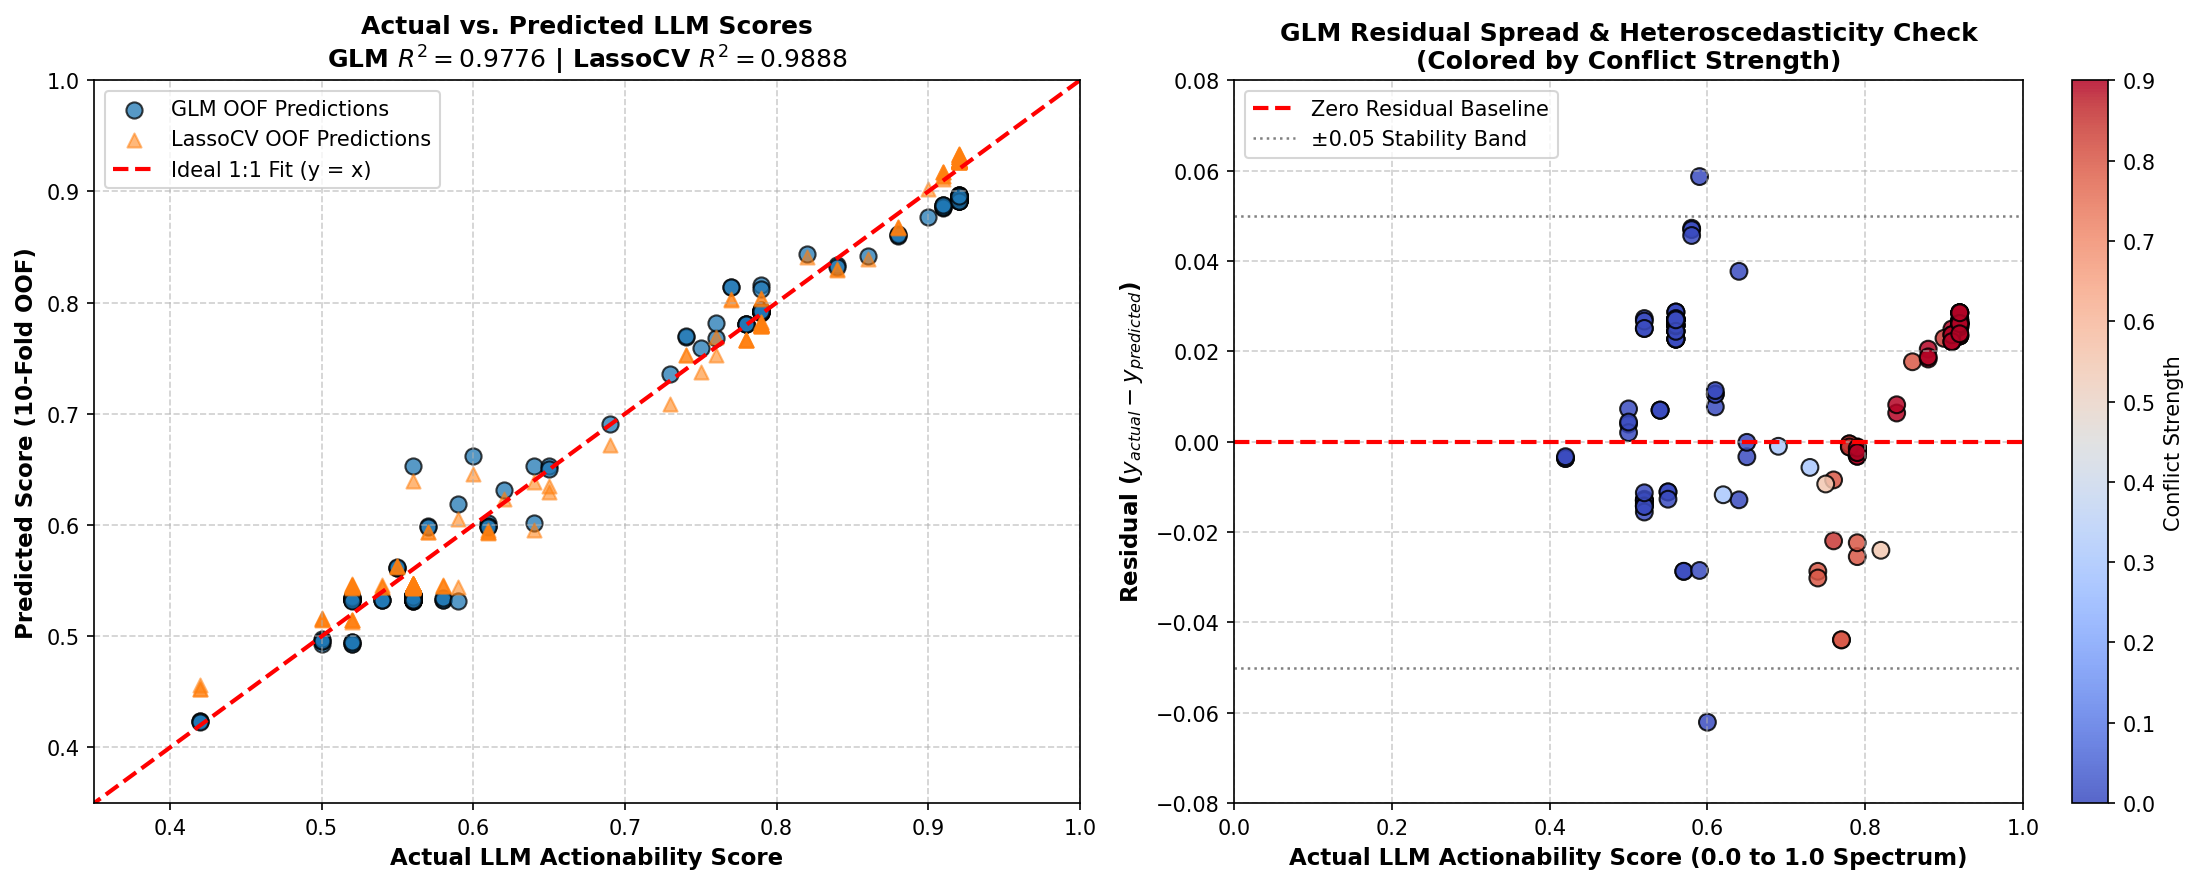

alt.HConcatChart(...)

In [ ]:
def run_statistical_model_validation(csv_path, selected_features, n_splits=10, random_state=42):
    """
    Executes 10-Fold Cross-Validation on Bounded Binomial GLM and LassoCV models,
    evaluating weight stability, MAE, Weighted MSE, aggregate R^2, and residual heteroscedasticity.
    """
    # 1. Load Data & Isolate Surviving Rubric Features
    df = pd.read_csv(csv_path)
    X = df[selected_features].copy()
    y = df['target_actionability_score'].copy()

    # Compute global inverse-frequency sample weights (matching modeling phase logic)
    score_counts = y.value_counts()
    inv_freq_map = 1.0 / score_counts
    inv_freq_map = inv_freq_map / inv_freq_map.mean()
    global_sample_weights = y.map(inv_freq_map).values

    # 2. Instantiate KFold Cross-Validator
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)

    # Execute baseline sklearn cross_val_score on LassoCV (unweighted fold check)
    scaler_global = StandardScaler()
    X_scaled_global = scaler_global.fit_transform(X)
    lasso_base = LassoCV(cv=5, random_state=random_state, alphas=np.logspace(-5, 1, 200))
    cv_scores_mae = -cross_val_score(
        lasso_base, X_scaled_global, y, cv=kf, scoring='neg_mean_absolute_error'
    )

    # Storage arrays for Out-of-Fold (OOF) predictions, metrics, and fold weights
    oof_preds_glm = np.zeros(len(df))
    oof_preds_lasso = np.zeros(len(df))

    glm_fold_mae, glm_fold_wmse, glm_fold_weights = [], [], []
    lasso_fold_mae, lasso_fold_wmse, lasso_fold_weights = [], [], []

    # 3. Execute 10-Fold Cross-Validation Loop (Leakage-Free Scaling & Weighting)
    for fold, (train_idx, val_idx) in enumerate(kf.split(X, y), 1):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

        # Calculate fold-specific training weights to mitigate the 0.56 cluster without leakage
        train_counts = y_train.value_counts()
        train_inv_freq = (1.0 / train_counts)
        train_inv_freq = train_inv_freq / train_inv_freq.mean()
        w_train = y_train.map(train_inv_freq).values
        w_val = global_sample_weights[val_idx]

        # Standardize strictly on training fold statistics
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_val_scaled = scaler.transform(X_val)

        # --- Model A: LassoCV ---
        lasso = LassoCV(cv=5, random_state=random_state, alphas=np.logspace(-5, 1, 200))
        lasso.fit(X_train_scaled, y_train, sample_weight=w_train)
        preds_lasso = lasso.predict(X_val_scaled)
        oof_preds_lasso[val_idx] = preds_lasso

        lasso_fold_mae.append(mean_absolute_error(y_val, preds_lasso))
        lasso_fold_wmse.append(mean_squared_error(y_val, preds_lasso, sample_weight=w_val))
        lasso_fold_weights.append(lasso.coef_)

        # --- Model B: Bounded GLM (Binomial Family, Logit Link) ---
        X_train_const = sm.add_constant(
            pd.DataFrame(X_train_scaled, columns=selected_features, index=X_train.index),
            has_constant='add'
        )
        X_val_const = sm.add_constant(
            pd.DataFrame(X_val_scaled, columns=selected_features, index=X_val.index),
            has_constant='add'
        )

        glm_model = sm.GLM(
            endog=y_train,
            exog=X_train_const,
            family=sm.families.Binomial(),
            freq_weights=w_train
        )
        glm_results = glm_model.fit()
        preds_glm = glm_results.predict(X_val_const)
        oof_preds_glm[val_idx] = preds_glm

        glm_fold_mae.append(mean_absolute_error(y_val, preds_glm))
        glm_fold_wmse.append(mean_squared_error(y_val, preds_glm, sample_weight=w_val))
        glm_fold_weights.append(glm_results.params.values)

    # 4. Calculate Aggregate Performance Metrics
    glm_r2 = r2_score(y, oof_preds_glm)
    glm_weighted_r2 = r2_score(y, oof_preds_glm, sample_weight=global_sample_weights)
    glm_mae_mean, glm_mae_std = np.mean(glm_fold_mae), np.std(glm_fold_mae)
    glm_wmse_mean, glm_wmse_std = np.mean(glm_fold_wmse), np.std(glm_fold_wmse)
    glm_violations = np.sum((oof_preds_glm < 0.0) | (oof_preds_glm > 1.0))

    lasso_r2 = r2_score(y, oof_preds_lasso)
    lasso_weighted_r2 = r2_score(y, oof_preds_lasso, sample_weight=global_sample_weights)
    lasso_mae_mean, lasso_mae_std = np.mean(lasso_fold_mae), np.std(lasso_fold_mae)
    lasso_wmse_mean, lasso_wmse_std = np.mean(lasso_fold_wmse), np.std(lasso_fold_wmse)
    lasso_violations = np.sum((oof_preds_lasso < 0.0) | (oof_preds_lasso > 1.0))

    print("=" * 65)
    print("STATISTICAL MODEL VALIDATION REPORT (10-FOLD CROSS-VALIDATION)")
    print("=" * 65)
    print(f"Total Evaluated Payloads: {len(df)} | Surviving Features: {selected_features}\n")

    print("--- 1. Bounded GLM (Binomial Family) ---")
    print(f"Aggregate OOF R^2 Score   : {glm_r2:.4f} (Weighted R^2: {glm_weighted_r2:.4f}) [Target >= 0.85]")
    print(f"10-Fold MAE (Mean +/- SD) : {glm_mae_mean:.4f} +/- {glm_mae_std:.4f} [Target SD <= 0.05]")
    print(f"10-Fold Weighted MSE      : {glm_wmse_mean:.6f} +/- {glm_wmse_std:.6f}")
    print(f"Boundary Violations       : {glm_violations} / {len(df)}\n")

    print("--- 2. LassoCV Regression ---")
    print(f"Aggregate OOF R^2 Score   : {lasso_r2:.4f} (Weighted R^2: {lasso_weighted_r2:.4f}) [Target >= 0.85]")
    print(f"10-Fold MAE (Mean +/- SD) : {lasso_mae_mean:.4f} +/- {lasso_mae_std:.4f} [Target SD <= 0.05]")
    print(f"Unweighted cross_val_score: {np.mean(cv_scores_mae):.4f} +/- {np.std(cv_scores_mae):.4f}")
    print(f"10-Fold Weighted MSE      : {lasso_wmse_mean:.6f} +/- {lasso_wmse_std:.6f}")
    print(f"Boundary Violations       : {lasso_violations} / {len(df)}\n")

    # Weight Stability Tables
    glm_w_df = pd.DataFrame(glm_fold_weights, columns=['const'] + selected_features)
    lasso_w_df = pd.DataFrame(lasso_fold_weights, columns=selected_features)

    print("--- 3. Parameter Stability Across 10 Folds ---")
    print("GLM Weights (Logit Scale):")
    print(pd.DataFrame({'Mean Weight': glm_w_df.mean(), 'Std Dev': glm_w_df.std()}).round(5))
    print("\nLassoCV Weights (Linear Scale):")
    print(pd.DataFrame({'Mean Weight': lasso_w_df.mean(), 'Std Dev': lasso_w_df.std()}).round(5))

    # Verify Success Criteria
    glm_passed = (glm_r2 >= 0.85) and (glm_mae_std <= 0.05)
    lasso_passed = (lasso_r2 >= 0.85) and (lasso_mae_std <= 0.05)
    print("\n" + "=" * 65)
    print(f"VALIDATION GATE STATUS -> GLM: {'PASSED' if glm_passed else 'FAILED'} | LassoCV: {'PASSED' if lasso_passed else 'FAILED'}")
    print("=" * 65)

    # 5. Residual Analysis & Heteroscedasticity Inspection
    df['glm_oof_pred'] = oof_preds_glm
    df['lasso_oof_pred'] = oof_preds_lasso
    df['glm_residual'] = df['target_actionability_score'] - df['glm_oof_pred']
    df['lasso_residual'] = df['target_actionability_score'] - df['lasso_oof_pred']

    fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=150)

    # Plot A: Actual vs. GLM Predicted Scatter Plot
    ax1 = axes[0]
    ax1.scatter(df['target_actionability_score'], df['glm_oof_pred'], alpha=0.75, c='#1f77b4', edgecolors='k', s=60, label='GLM OOF Predictions')
    ax1.scatter(df['target_actionability_score'], df['lasso_oof_pred'], alpha=0.55, c='#ff7f0e', marker='^', s=45, label='LassoCV OOF Predictions')
    ax1.plot([0.0, 1.0], [0.0, 1.0], 'r--', lw=2, label='Ideal 1:1 Fit (y = x)')
    ax1.set_xlim(0.35, 1.0)
    ax1.set_ylim(0.35, 1.0)
    ax1.set_xlabel('Actual LLM Actionability Score', fontsize=11, fontweight='bold')
    ax1.set_ylabel('Predicted Score (10-Fold OOF)', fontsize=11, fontweight='bold')
    ax1.set_title(f'Actual vs. Predicted LLM Scores\nGLM $R^2 = {glm_r2:.4f}$ | LassoCV $R^2 = {lasso_r2:.4f}$', fontsize=12, fontweight='bold')
    ax1.legend(loc='upper left', frameon=True)
    ax1.grid(True, linestyle='--', alpha=0.6)

    # Plot B: Residual Spread Across 0.0 to 1.0 Spectrum
    ax2 = axes[1]
    sc = ax2.scatter(
        df['target_actionability_score'], df['glm_residual'],
        c=df['conflict_strength'], cmap='coolwarm', edgecolors='k', s=65, alpha=0.85
    )
    ax2.axhline(0.0, color='red', linestyle='--', lw=2, label='Zero Residual Baseline')
    ax2.axhline(0.05, color='gray', linestyle=':', lw=1.2, label='±0.05 Stability Band')
    ax2.axhline(-0.05, color='gray', linestyle=':', lw=1.2)
    ax2.set_xlim(0.0, 1.0)
    ax2.set_ylim(-0.08, 0.08)
    ax2.set_xlabel('Actual LLM Actionability Score (0.0 to 1.0 Spectrum)', fontsize=11, fontweight='bold')
    ax2.set_ylabel('Residual ($y_{actual} - y_{predicted}$)', fontsize=11, fontweight='bold')
    ax2.set_title('GLM Residual Spread & Heteroscedasticity Check\n(Colored by Conflict Strength)', fontsize=12, fontweight='bold')
    cbar = plt.colorbar(sc, ax=ax2)
    cbar.set_label('Conflict Strength', fontsize=10)
    ax2.legend(loc='upper left', frameon=True)
    ax2.grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.savefig('statistical_model_validation_diagnostics.png', dpi=150)
    plt.show()

    # Interactive Altair Scatter + Residual Chart (matching notebook style)
    scatter_chart = alt.Chart(df).mark_circle(size=70, opacity=0.8, stroke='black', strokeWidth=0.5).encode(
        x=alt.X('target_actionability_score:Q', title='Actual LLM Score', scale=alt.Scale(domain=[0.35, 1.0])),
        y=alt.Y('glm_oof_pred:Q', title='GLM Out-of-Fold Predicted Score', scale=alt.Scale(domain=[0.35, 1.0])),
        color=alt.Color('conflict_strength:Q', scale=alt.Scale(scheme='redblue', reverse=True), title='Conflict Strength'),
        tooltip=['file_name', 'topic_id', 'target_actionability_score', alt.Tooltip('glm_oof_pred:Q', format='.4f'), alt.Tooltip('glm_residual:Q', format='.4f')]
    ).properties(title='Interactive GLM Validation: Actual vs. Predicted', width=380, height=350)

    ideal_line = alt.Chart(pd.DataFrame({'x': [0.35, 1.0], 'y': [0.35, 1.0]})).mark_line(
        color='red', strokeDash=[5, 5]
    ).encode(x='x:Q', y='y:Q')

    res_chart = alt.Chart(df).mark_circle(size=70, opacity=0.8, stroke='black', strokeWidth=0.5).encode(
        x=alt.X('target_actionability_score:Q', title='Actual LLM Score (0.0 - 1.0 Spectrum)', scale=alt.Scale(domain=[0.0, 1.0])),
        y=alt.Y('glm_residual:Q', title='Residual (Actual - GLM Predicted)', scale=alt.Scale(domain=[-0.08, 0.08])),
        color=alt.Color('conflict_strength:Q', scale=alt.Scale(scheme='redblue', reverse=True)),
        tooltip=['file_name', 'topic_id', 'target_actionability_score', alt.Tooltip('glm_oof_pred:Q', format='.4f'), alt.Tooltip('glm_residual:Q', format='.4f')]
    ).properties(title='Interactive Residual Spread Across Score Spectrum', width=380, height=350)

    zero_line = alt.Chart(pd.DataFrame({'y': [0.0]})).mark_rule(color='red', strokeDash=[5, 5]).encode(y='y:Q')

    combined_altair = alt.hconcat((scatter_chart + ideal_line), (res_chart + zero_line)).interactive()
    display(combined_altair)

    return df, glm_w_df, lasso_w_df

# Execute Validation Pipeline
validated_df, glm_weights_cv, lasso_weights_cv = run_statistical_model_validation(
    data_csv_path, surviving_features
)

# EVALUATION OF 3 DIMENSIONAL RUBRIC - UTILIZING THE TRAINED WEIGHTS AND STANDARDISED FEATURES

In [ ]:
import pandas as pd
import numpy as np

# 1. Load the 172-record training dataset generated in Phase 1
df = pd.read_csv("/content/flattened_topic_features.csv")

# 2. Isolate the 3 empirically validated core dimensions
CORE_3 = ["conflict_strength", "supporting_evidence", "coordination_value"]

# 3. Calculate the Means
# Averages the 172 values for each column respectively
means = df[CORE_3].mean().values

# 4. Calculate the Standard Deviations
# ddof=0 (Delta Degrees of Freedom = 0) is mandatory.
# Pandas defaults to ddof=1 (sample SD), but scikit-learn's StandardScaler
# uses ddof=0 (population SD). You must use ddof=0 to match the ML model.
stds = df[CORE_3].std(ddof=0).values

# 5. Output the arrays to paste into the CandidateIntelligenceEngine config
print("MEANS: ", np.round(means, 4))
print("STDS:  ", np.round(stds, 4))

In [ ]:
# =====================================================================
# TOPIC PAYLOAD EVALUATION HARNESS BYPASSING STAGES 1-4 - WITH CORRECT MEAND AND SD
# =====================================================================

FROZEN_DIR = Path("/content/drive/MyDrive/Datasets/enriched_topic_payloads")
CSV_PATH = Path("/content/flattened_topic_features.csv")
EVAL_OUTPUT_DIR = Path("/content/drive/MyDrive/Datasets/frozen_evaluation_results_3dim")
EVAL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Load offline scaler parameters and model coefficients
CORE_3 = ["conflict_strength", "supporting_evidence", "coordination_value"]
df_hist = pd.read_csv(CSV_PATH)
# Standardization parameters from training dataset
means = df_hist[CORE_3].mean().values
stds = df_hist[CORE_3].std(ddof=0).values

# Untouched Raw Coefficients + Standardized Features + Intercept from our Notebook ML run
# GLM
GLM_CONST = 0.928932
GLM_COEFS = np.array([0.585327, 0.220925, 0.158183])

# LassoCV
LASSO_COEFS = np.array([0.113945, 0.040063, 0.031245])
y_hist = df_hist['target_actionability_score']
score_counts = y_hist.value_counts()
inv_freq_map = 1.0 / score_counts
inv_freq_map = inv_freq_map / inv_freq_map.mean()
sample_weights_hist = y_hist.map(inv_freq_map).values
LASSO_CONST = float(np.average(y_hist, weights=sample_weights_hist))

def predict_exact_glm(c_val, s_val, coord_val):
    x_raw = np.array([c_val, s_val, coord_val])
    x_scaled = (x_raw - means) / stds
    z = GLM_CONST + np.dot(x_scaled, GLM_COEFS)
    return round(float(1.0 / (1.0 + np.exp(-z))), 2)

def predict_exact_lasso(c_val, s_val, coord_val):
    x_raw = np.array([c_val, s_val, coord_val])
    x_scaled = (x_raw - means) / stds
    y_pred = LASSO_CONST + np.dot(x_scaled, LASSO_COEFS)
    return round(float(np.clip(y_pred, 0.0, 1.0)), 2)

# 2. Discover all 50 frozen thread-level ranked JSON files
ranked_files = sorted(glob.glob(str(FROZEN_DIR / "conv_*_ranked.json")))
print(f"[*] Found {len(ranked_files)} frozen thread-level ranked files.")

intel_engine = CandidateIntelligenceEngine()
comparison_rows = []
rank_flips = 0
total_multi_topic_threads = 0

# Set call_live_llm=True to call the new 3-dim LLM prompt on every frozen payload,
# or False to evaluate instantaneously using the frozen clamped 3-dim values.
CALL_LIVE_LLM = True

for idx, r_file in enumerate(ranked_files, start=1):
    with open(r_file, "r", encoding="utf-8") as f:
        thread_data = json.load(f)

    thread_id = thread_data.get("thread_id", f"thread-{idx}")
    old_candidates = thread_data.get("candidates", [])
    if not old_candidates:
        continue

    new_scored_list = []
    old_order = [c.get("topic_id") for c in old_candidates]

    for cand in old_candidates:
        topic_id = cand.get("topic_id")
        old_rank = cand.get("rank")
        old_designation = cand.get("designation")
        old_details = cand.get("candidate_details", {})
        old_score = float(cand.get("score", old_details.get("score", 0.0)))
        old_threshold_res = old_details.get("threshold_result", "QUALIFIED" if old_score >= 0.60 else "CONTINUE_MONITORING")
        old_breakdown = old_details.get("score_breakdown", {})

        # ISOLATE FROZEN STAGE 4 ENRICHED TOPIC PAYLOAD (100% Frozen Ground Truth)
        frozen_enriched_topic = old_details.get("enriched_topic", {})

        if CALL_LIVE_LLM:
            time.sleep(0.25)  # Rate-limit safety
            new_scored = intel_engine.score_candidate(
                enriched_candidate=frozen_enriched_topic,
                threshold=0.60
            )
        else:
            # Instantaneous offline evaluation on frozen breakdown
            c_s = float(old_breakdown.get("conflict_strength", 0.0))
            s_e = float(old_breakdown.get("supporting_evidence", 0.0))
            c_v = float(old_breakdown.get("coordination_value", 0.0))
            # w_score = round(0.6151 * c_s + 0.2163 * s_e + 0.1687 * c_v, 2)
            w_score = predict_exact_lasso(c_s, s_e, c_v)
            new_scored = {
                "topic_id": topic_id,
                "enriched_topic": frozen_enriched_topic,
                "score": w_score,
                "threshold": 0.60,
                "score_breakdown": {"conflict_strength": c_s, "supporting_evidence": s_e, "coordination_value": c_v},
                "threshold_result": "QUALIFIED" if w_score >= 0.60 else "CONTINUE_MONITORING",
                "reasons": old_details.get("reasons", [])
            }

        # Also compute exact Standardized GLM Logit score and Lasso scores on the new 3 dimensions
        nb = new_scored["score_breakdown"]
        glm_exact_score = predict_exact_glm(
            nb["conflict_strength"], nb["supporting_evidence"], nb["coordination_value"]
        )
        lasso_exact_score = predict_exact_lasso(
            nb["conflict_strength"], nb["supporting_evidence"], nb["coordination_value"]
        )
        new_scored["score"] = lasso_exact_score  # Set the primary score column to Scenario 1 Lasso
        new_scored["glm_logit_score"] = glm_exact_score
        new_scored["_old_meta"] = {
            "old_rank": old_rank,
            "old_designation": old_designation,
            "old_score": old_score,
            "old_threshold_res": old_threshold_res,
            "old_conflict": float(old_breakdown.get("conflict_strength", 0.0)),
            "old_evidence": float(old_breakdown.get("supporting_evidence", 0.0)),
            "old_coord": float(old_breakdown.get("coordination_value", 0.0)),
        }
        new_scored_list.append(new_scored)

    # Re-run Stage 6 deterministic multi-key ranking on the newly scored candidates
    new_ranked_set = intel_engine.rank_candidates(
        qualified_candidates=new_scored_list,
        thread_id=thread_id
    )
    new_candidates = new_ranked_set.get("candidates", [])
    new_order = [c.get("topic_id") for c in new_candidates]

    if len(old_candidates) > 1:
        total_multi_topic_threads += 1
        if old_order != new_order:
            rank_flips += 1

    # Record per-topic deltas
    for new_c in new_candidates:
        t_id = new_c.get("topic_id")
        new_rank = new_c.get("rank")
        new_desig = new_c.get("designation")
        details = new_c.get("candidate_details", {})
        old_m = details.pop("_old_meta", {})
        nb = details.get("score_breakdown", {})

        comparison_rows.append({
            "thread_id": thread_id,
            "topic_id": t_id,
            "old_score_8dim": old_m.get("old_score"),
            "new_score_3dim_weighted": new_c.get("score"),
            "new_score_glm_logit": details.get("glm_logit_score"),
            "score_delta_weighted": round(new_c.get("score") - old_m.get("old_score"), 4),
            "score_delta_glm": round(details.get("glm_logit_score") - old_m.get("old_score"), 4),
            "old_rank": old_m.get("old_rank"),
            "new_rank": new_rank,
            "rank_preserved": old_m.get("old_rank") == new_rank,
            "old_verdict": old_m.get("old_threshold_res"),
            "new_verdict_weighted": "QUALIFIED" if new_c.get("score") >= 0.60 else "CONTINUE_MONITORING",
            "new_verdict_glm": "QUALIFIED" if details.get("glm_logit_score") >= 0.60 else "CONTINUE_MONITORING",
            "old_conflict": old_m.get("old_conflict"),
            "new_conflict": nb.get("conflict_strength"),
            "old_evidence": old_m.get("old_evidence"),
            "new_evidence": nb.get("supporting_evidence"),
            "old_coord": old_m.get("old_coord"),
            "new_coord": nb.get("coordination_value"),
        })

    # Save updated ranked JSON artifact
    out_path = EVAL_OUTPUT_DIR / Path(r_file).name.replace("_ranked.json", "_3dim_ranked.json")
    with open(out_path, "w", encoding="utf-8") as out_f:
        json.dump(new_ranked_set, out_f, indent=2)

# 3. Compile Summary Metrics
eval_df = pd.DataFrame(comparison_rows)
eval_df.to_csv(EVAL_OUTPUT_DIR / "frozen_payload_delta_audit.csv", index=False)

print("\n" + "=" * 80)
print("FROZEN PAYLOAD EVALUATION HARNESS — EMPIRICAL DELTA REPORT")
print("=" * 80)
print(f"Total Frozen Payloads Evaluated : {len(eval_df)}")
print(f"Exact Rank Preservation Rate    : {(eval_df['rank_preserved'].mean() * 100):.2f}%")
if total_multi_topic_threads > 0:
    print(f"Multi-Topic Thread Order Flips  : {rank_flips} / {total_multi_topic_threads} threads")


for label, col, v_col in [
    ("3-Dim Standardized Lasso Regression", "new_score_3dim_weighted", "new_verdict_weighted"),
    ("3-Dim Standardized GLM Logit Curve", "new_score_glm_logit", "new_verdict_glm")
]:
    mae = mean_absolute_error(eval_df["old_score_8dim"], eval_df[col])
    rmse = np.sqrt(mean_squared_error(eval_df["old_score_8dim"], eval_df[col]))
    y_true_bin = (eval_df["old_verdict"] == "QUALIFIED").astype(int)
    y_pred_bin = (eval_df[v_col] == "QUALIFIED").astype(int)
    agreement = (y_true_bin == y_pred_bin).mean() * 100
    f1 = f1_score(y_true_bin, y_pred_bin, zero_division=1)
    print(f"\n--- {label} ---")
    print(f" • MAE vs 8-Dim Baseline        : {mae:.4f}")
    print(f" • RMSE vs 8-Dim Baseline       : {rmse:.4f}")
    print(f" • Threshold Agreement (0.60)   : {agreement:.2f}% (F1 = {f1:.4f})")

print("\nSample Delta Audit (First 5 Topics):")
print(eval_df[["thread_id", "topic_id", "old_score_8dim", "new_score_3dim_weighted", "new_score_glm_logit", "old_rank", "new_rank", "rank_preserved"]].head(5))

[*] Found 50 frozen thread-level ranked files.

FROZEN PAYLOAD EVALUATION HARNESS — EMPIRICAL DELTA REPORT
Total Frozen Payloads Evaluated : 172
Exact Rank Preservation Rate    : 66.28%
Multi-Topic Thread Order Flips  : 9 / 18 threads

--- 3-Dim Standardized Lasso Regression ---
 • MAE vs 8-Dim Baseline        : 0.0685
 • RMSE vs 8-Dim Baseline       : 0.0809
 • Threshold Agreement (0.60)   : 94.19% (F1 = 0.9425)

--- 3-Dim Standardized GLM Logit Curve ---
 • MAE vs 8-Dim Baseline        : 0.0817
 • RMSE vs 8-Dim Baseline       : 0.0996
 • Threshold Agreement (0.60)   : 94.19% (F1 = 0.9425)

Sample Delta Audit (First 5 Topics):
  thread_id   topic_id   old_score_8dim  new_score_3dim_weighted  \
0  post-1001  topic-001       0.92                0.88             
1  post-1002  topic-001       0.92                0.88             
2  post-1002  topic-002       0.73                0.71             
3  post-1003  topic-001       0.92                0.88             
4  post-1003  topic-002 

In [ ]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.colheader_justify", "center")
display(eval_df[["thread_id", "topic_id", "old_score_8dim", "new_score_3dim_weighted", "new_score_glm_logit", "old_rank", "new_rank", "rank_preserved"]].head(10))

,thread_id,topic_id,old_score_8dim,new_score_3dim_weighted,new_score_glm_logit,old_rank,new_rank,rank_preserved
0,post-1001,topic-001,0.92,0.88,0.87,1,1,True
1,post-1002,topic-001,0.92,0.88,0.87,1,1,True
2,post-1002,topic-002,0.73,0.71,0.74,2,2,True
3,post-1003,topic-001,0.92,0.88,0.87,1,1,True
4,post-1003,topic-002,0.64,0.50,0.49,2,2,True
5,post-1003,topic-003,0.56,0.45,0.42,3,3,True
6,post-1004,topic-001,0.92,0.88,0.87,1,1,True
7,post-1005,topic-001,0.92,0.88,0.87,1,1,True
8,post-1005,topic-002,0.56,0.45,0.42,2,2,True
9,post-1006,topic-001,0.92,0.88,0.87,1,1,True


In [ ]:
# =====================================================================
# IMPACT ANALYSIS PROGRAM: RANK FLIPS, TIER STABILITY & THRESHOLD AUDIT
# =====================================================================
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import confusion_matrix

AUDIT_CSV = Path("/content/drive/MyDrive/Datasets/frozen_evaluation_results_3dim/frozen_payload_delta_audit.csv")
df_audit = pd.read_csv(AUDIT_CSV)

# Map designations based on Stage 6 ranking rules (Rank 1=PRIMARY, Rank 2=SECONDARY, Rank >=3=TERTIARY)
def get_designation(rank):
    if rank == 1:
        return "PRIMARY (Rank 1)"
    elif rank == 2:
        return "SECONDARY (Rank 2)"
    return "TERTIARY (Rank 3+)"

df_audit["old_tier"] = df_audit["old_rank"].apply(get_designation)
df_audit["new_tier_lasso"] = df_audit["new_rank"].apply(get_designation)

# Also compute independent deterministic ranks for GLM Logit (matching Stage 6 multi-key sort)
df_audit = df_audit.sort_values(
    by=["thread_id", "new_score_glm_logit", "new_conflict", "new_coord"],
    ascending=[True, False, False, False]
)
df_audit["new_rank_glm"] = df_audit.groupby("thread_id").cumcount() + 1
df_audit["rank_preserved_glm"] = df_audit["old_rank"] == df_audit["new_rank_glm"]
df_audit["new_tier_glm"] = df_audit["new_rank_glm"].apply(get_designation)

# Sort back to original thread & rank order for clean reporting
df_audit = df_audit.sort_values(by=["thread_id", "old_rank"]).reset_index(drop=True)

print("=" * 85)
print("1. TIER-STRATIFIED RANK PRESERVATION (PRIMARY vs. SECONDARY vs. TERTIARY)")
print("=" * 85)
tier_summary = df_audit.groupby("old_tier").agg(
    Total_Topics=("topic_id", "count"),
    Lasso_Exact_Rank_Match=("rank_preserved", lambda x: f"{x.sum()} / {len(x)} ({x.mean()*100:.2f}%)"),
    GLM_Exact_Rank_Match=("rank_preserved_glm", lambda x: f"{x.sum()} / {len(x)} ({x.mean()*100:.2f}%)")
).loc[["PRIMARY (Rank 1)", "SECONDARY (Rank 2)", "TERTIARY (Rank 3+)"]]
print(tier_summary.to_string())

# ---------------------------------------------------------------------
# 2. MULTI-TOPIC THREAD FLIP ANATOMY (18 Multi-Topic Threads)
# ---------------------------------------------------------------------
print("\n" + "=" * 85)
print("2. ANATOMY OF THE MULTI-TOPIC THREAD ORDER FLIPS (PRIMARY vs. LOWER-TIER SWAPS)")
print("=" * 85)

thread_counts = df_audit.groupby("thread_id")["topic_id"].count()
multi_threads = thread_counts[thread_counts > 1].index.tolist()

primary_touched_threads = []
sec_tert_only_threads = []
unflipped_threads = []

for tid in multi_threads:
    sub = df_audit[df_audit["thread_id"] == tid]
    if (sub["old_rank"] == sub["new_rank"]).all():
        unflipped_threads.append(tid)
    else:
        # Check if the original Rank 1 (Primary) topic stayed at Rank 1
        old_p = sub[sub["old_rank"] == 1]["topic_id"].values[0]
        new_p = sub[sub["new_rank"] == 1]["topic_id"].values[0]
        if old_p == new_p:
            sec_tert_only_threads.append(tid)
        else:
            primary_touched_threads.append(tid)

print(f"Total Multi-Topic Threads Evaluated            : {len(multi_threads)}")
print(f" • 100% Order Preserved (Zero Flips)           : {len(unflipped_threads)} threads")
print(f" • Flips Strictly Between Secondary & Tertiary : {len(sec_tert_only_threads)} threads -> {sec_tert_only_threads}")
print(f" • Flips Touching Primary (Rank 1) Slot        : {len(primary_touched_threads)} threads -> {primary_touched_threads}")

if primary_touched_threads:
    print("\n[Deep-Dive: Threads Where Primary (Rank 1) Shifted]")
    cols = ["thread_id", "topic_id", "old_rank", "new_rank", "old_score_8dim", "new_score_glm_logit", "new_conflict", "new_evidence", "new_coord"]
    print(df_audit[df_audit["thread_id"].isin(primary_touched_threads) & (df_audit["old_rank"].isin([1, 2]) | df_audit["new_rank"].isin([1, 2]))][cols].to_string(index=False))

if sec_tert_only_threads:
    print("\n[Deep-Dive: Sample Secondary/Tertiary Swaps (Rank 1 Untouched)]")
    cols = ["thread_id", "topic_id", "old_rank", "new_rank", "old_score_8dim", "new_score_glm_logit", "old_verdict", "new_verdict_glm"]
    print(df_audit[df_audit["thread_id"].isin(sec_tert_only_threads) & (df_audit["old_rank"] != df_audit["new_rank"])][cols].head(15).to_string(index=False))

# ---------------------------------------------------------------------
# 3. THRESHOLD AGREEMENT & DISAGREEMENT AUDIT (0.60 QUALIFICATION GATE)
# ---------------------------------------------------------------------
print("\n" + "=" * 85)
print("3. THRESHOLD AGREEMENT AUDIT (0.60 QUALIFIED vs. CONTINUE_MONITORING)")
print("=" * 85)

cm = confusion_matrix(
    df_audit["old_verdict"],
    df_audit["new_verdict_glm"],
    labels=["QUALIFIED", "CONTINUE_MONITORING"]
)
cm_df = pd.DataFrame(
    cm,
    index=["8-Dim: QUALIFIED", "8-Dim: CONTINUE_MONITORING"],
    columns=["3-Dim GLM: QUALIFIED", "3-Dim GLM: CONTINUE_MONITORING"]
)
print(cm_df.to_string())

disagreements = df_audit[df_audit["old_verdict"] != df_audit["new_verdict_glm"]]
print(f"\nTotal Threshold Disagreements: {len(disagreements)} / {len(df_audit)} payloads ({len(disagreements)/len(df_audit)*100:.2f}%)")
if not disagreements.empty:
    d_cols = ["thread_id", "topic_id", "old_rank", "new_rank", "old_score_8dim", "new_score_glm_logit", "old_verdict", "new_verdict_glm", "new_conflict", "new_evidence", "new_coord"]
    print(disagreements[d_cols].to_string(index=False))

1. TIER-STRATIFIED RANK PRESERVATION (PRIMARY vs. SECONDARY vs. TERTIARY)
                    Total_Topics Lasso_Exact_Rank_Match GLM_Exact_Rank_Match
old_tier                                                                    
PRIMARY (Rank 1)          50        50 / 50 (100.00%)     50 / 50 (100.00%) 
SECONDARY (Rank 2)        18         16 / 18 (88.89%)      16 / 18 (88.89%) 
TERTIARY (Rank 3+)       104        48 / 104 (46.15%)     48 / 104 (46.15%) 

2. ANATOMY OF THE MULTI-TOPIC THREAD ORDER FLIPS (PRIMARY vs. LOWER-TIER SWAPS)
Total Multi-Topic Threads Evaluated            : 18
 • 100% Order Preserved (Zero Flips)           : 9 threads
 • Flips Strictly Between Secondary & Tertiary : 9 threads -> ['post-1012', 'post-1016', 'post-1023', 'post-1024', 'post-1025', 'post-1026', 'post-1030', 'post-1048', 'post-1049']
 • Flips Touching Primary (Rank 1) Slot        : 0 threads -> []

[Deep-Dive: Sample Secondary/Tertiary Swaps (Rank 1 Untouched)]
thread_id    topic_id    old_rank  new_